# AIR proposal v2: explicit correspondence chain + Laplace mixture vs the pooled flow proposal

Issue #21. Spec: `docs/a2b_air_proposal_v2_2026-11-03.md` (Tim, 2026-11-03), incl. its *Refinement* section
(Gauss–Newton builds q, no MCMC; forward–backward; C_a widened by σ_A). Branch `exp/21-air-chain`.

## Description

<!-- Written before the first run (2026-11-03). -->

**Question.** Pilot 3's proposal q(θ | A, B) (pooled encoder + spline flow, notebook 11) underfits: the gap
KL(post ‖ q) grows with n_A (pilot-2 diagnostics: 0.28 / 0.94 / 1.08 nats at n_A = 1 / 5 / 10, J = 2). The
proposal v2 claim: a proposal built from **explicit per-point correspondence evidence** has no pooled bottleneck
and no branch averaging, so at equal K it should give higher ESS and a smaller NLL gap to the exact reference,
increasingly so for larger n_A and wigglier g. If true, the d ≥ 2 work becomes learned message passing over location
beliefs; if not, the bottleneck is elsewhere (decoder, or the transform prior itself).

**Setup.** Variant (c) of the spec, no learned parts (`experimental/air/chain.py`):
1. *B model*: a GP on B (RBF, ML over a lengthscale × noise grid) → predictive mean/var on a G = 256 grid of u ∈ [0, 1].
2. *Evidence volumes* C_a(u) = mean_s N(y_a; m_B(u), v_B(u) + s²) over 4 values s of σ_A's prior range
   (σ_A is latent; the fits use s = 0.02).
3. *Coherence*: 1-D chain over A sorted by x; transitions p(u_{a+1} | u_a) estimated from S = 4096 prior draws of θ
   (KDE, bandwidth 0.02); forward filtering, backward sampling of M = 128 correspondence sets.
4. *Fit*: per set, Levenberg–Marquardt for θ in whitened prior coordinates, first to the correspondences (τ = 0.03),
   then to the evidence objective; Laplace covariance (I + JᵀJ)⁻¹.
5. *Proposal*: q = (1 − ε)·(1/M) Σ_m N(θ̂_m, Σ_m) + ε·prior, ε = 0.1 (the same defensive ε as pilot 3's flow).

Compared at equal K ∈ {8, 32, 128} importance samples, with pilot 3's decoder (σ-conditioned, Σ = 0) as the
likelihood, on pilot 3's evaluation tasks (`eval_tasks(J, 256, 777, ecdf)`, J ∈ {2, 16}, n_A ∈ {1, 2, 3, 5, 10}):
- `flow` = (a): pilot 3's trained proposal of the same seed and J (with its ε-prior mixture);
- `flow_gn`: the flow's M = 128 draws as seeds → Gauss–Newton + Laplace mixture (refinement §1: the flow proposes,
  GN sharpens);
- `chain_gp` = (c);
- `chain_oracle` = (c) with the true g as B model (an upper bound on what better emissions, variant (d), could give);
- `grid` (J = 2 only): the exact dense-B Bayes reference on a 101² θ grid (pilot 3's G-ref).
For J = 16 there is no exact reference: methods are compared with each other and with pilot 3's `isref`
(K = 4096, same tasks, from snapshot `results/air_rb/<pilot-3 eval>`) by task id.
Seeds 0, 1, 2 = pilot 3's checkpoint seeds (decoder and proposals of that seed); the tasks are the same for all seeds.

**What to look for.**
- NLL(method, K) − NLL(grid) at J = 2 and NLL(flow) − NLL(chain_gp) at J = 2, 16, per n_A and K; paired by task.
- ESS/K per proposal; `logq_true` (density of q at the true θ); `rank_true` (share of q draws with higher q density
  than θ_true; uniform if q is calibrated, piled at 1 if q misses θ_true); KL(post ‖ q) at J = 2 (64 tasks).
- All of the above by the number of branches of g (monotone pieces), and the build cost per task.

**Pre-registered criteria** (paired mean over 256 tasks; a "cell" is (J, n_A); a criterion holds if it holds in each
of the 3 seeds):
- **V2.0 sanity**: at J = 2, n_A ≤ 3, chain_oracle NLL at K = 128 within 0.05 nats of pilot 3's `isref` (prior IS,
  K = 4096, the same decoder; joined by seed and task); chain_oracle KL(post ‖ q) ≤ chain_gp KL + 0.05 (better
  emissions do not hurt).
  *Amended 2026-11-03, before the first pilot run:* the original reference was `grid`, which uses the exact
  likelihood, so every proposal (also pilot 3's flow) sits ~0.15 nats above it because of the shared decoder
  (see Limits), and V2.0 could not pass whatever the proposal. `isref` has the same likelihood as the methods, so
  method − isref is the proposal's error alone. Noticed while preparing the analysis on the scratch probe tables;
  no pilot data had been produced. method − grid is still reported.
- **V2.1 primary**: at K = 32, NLL(flow) − NLL(chain_gp) ≥ 0.05 nats in at least 2 of the 3 cells n_A ∈ {3, 5, 10},
  for both J = 2 and J = 16.
- **V2.2**: ESS/K(chain_gp) > ESS/K(flow) at K = 32 in the same cells.
- **V2.1b** (reported, not gating): the same comparison for `flow_gn` vs `flow` (does GN + Laplace fix the flow's width?).
- **V2.3 n_A = 1**: |NLL(flow) − NLL(chain_gp)| ≤ 0.05 (the spec expects (a) to stay competitive; reported, not gating).
- **V2.4 branches**: the flow − chain_gp gap at n_A ≥ 3 increases with the branch count of g (reported, not gating).

**GO / NO-GO.** GO if V2.0, V2.1 and V2.2 hold: build the d ≥ 2 version (learned message passing over location
beliefs) and the J-sampled prior. NO-GO if NLL(flow) − NLL(chain_gp) < 0.02 in every cell with n_A ≥ 2 at
K = 32 (explicit correspondences buy nothing over the flow; the bottleneck is elsewhere). Otherwise INCONCLUSIVE.
If V2.0 fails, the result is INCONCLUSIVE regardless (the chain construction itself is broken).

**Limits.**
- 1-D, h = id, and **J known** (J = 2 or 16, fixed per run). The spec's setup samples J per task with a Laplace-evidence
  mixture over J; that needs a J-sampled training prior for decoder and flow. Staged next (isolation, not a scope cut).
- Only (a) and (c) (plus the oracle-emission bound). (b) transport-token loop + flow and (d) learned emissions are
  staged after this (they need training); `chain_oracle` bounds what (d) can gain.
- The likelihood is the trained decoder, not the exact one, so all methods share its error; at J = 2 `grid` uses the
  exact likelihood, so method − grid contains the decoder gap (~0.1–0.2 nats in pilot 2) in addition to the proposal gap.
  The comparison flow vs chain at equal K is unaffected.
- The chain's transitions use a KDE over prior samples: fine in 1-D, no claim about d ≥ 2.
- Pilot only (split 0 tasks, seed 777); nothing here is tuned on split 1.


## Results

Sweeps: `pilot_20261104-001215` (seed 0), `pilot_20261104-004520` (seed 1), `pilot_20261104-011821` (seed 2). Each sweep has one member per J (the comma in `task.proposal_ckpts` is a sweep axis); tables are concatenated. `isref` = pilot 3's prior-IS (J = 2) / q-IS (J = 16) reference with K = 4096 and the same decoder, from pilot 3's evaluation snapshots of the same seed (`pilot3_isref.parquet`).

In [ ]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from meta_pfn.utils.env import repo_root

ROOT = Path('results/air_chain'); ROOT = ROOT if ROOT.is_absolute() else repo_root() / ROOT
SW = {'pilot_20261104-001215': 0, 'pilot_20261104-004520': 1, 'pilot_20261104-011821': 2}
def tab(name):
    return pd.concat([pd.read_parquet(ROOT / s / "tables" / f"{name}.parquet").assign(seed=i) for s, i in SW.items()],
                     ignore_index=True)
for s in SW:
    m = ROOT / s / "manifest.json"
    print(s, "seed", SW[s], json.loads(m.read_text())["status_counts"] if m.exists() else "(no manifest: scratch)")
NLL, DIAG = tab("nll"), tab("diag")
INFO = tab("task_info").pivot_table(index=["J", "task"], values=[c for c in ("branches", "gp_ell", "gp_sn", "sig_a") if c in tab("task_info")]).reset_index()
NLL[["prop", "K"]] = NLL.method.str.extract(r"^(.*)_K(\d+)$"); NLL["K"] = NLL.K.astype(float)
ISR = pd.read_parquet(ROOT / "pilot3_isref.parquet") if (ROOT / "pilot3_isref.parquet").exists() else None
SEEDS = sorted(NLL.seed.unique()); NS = len(SEEDS); PROPS = ["flow", "flow_gn", "chain_gp", "chain_oracle"]
print("seeds", SEEDS, "| tasks per (J, n_A):", NLL.task.nunique(), "| isref joined:", ISR is not None)
C = {"flow": "#2a78d6", "flow_gn": "#13a4b4", "chain_gp": "#e8743b", "chain_oracle": "#945ecf"}
INK = "#2b2b2b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6",
                     "axes.edgecolor": "#9a9a9a", "font.size": 9, "lines.linewidth": 2})

def cell_mean(prop, K, J):
    x = NLL[(NLL.prop == prop) & (NLL.K == K) & (NLL.J == J)]
    return x.groupby(["seed", "n_a", "task"]).nll.mean()

def paired(a, b):
    """a − b per task, then mean per (seed, n_a); returns (seed-mean, seed-SE, task-SE) per n_a."""
    d = (a - b).dropna().rename("d").reset_index()
    ps = d.groupby(["seed", "n_a"]).d.mean().unstack("seed")
    tse = d.groupby("n_a").d.std() / np.sqrt(d.groupby("n_a").d.count())
    return pd.DataFrame({"mean": ps.mean(axis=1), "seed_se": ps.std(axis=1) / np.sqrt(ps.shape[1]) if ps.shape[1] > 1 else np.nan,
                         "task_se": tse, "min_over_seeds": ps.min(axis=1), "max_over_seeds": ps.max(axis=1)})


pilot_20261104-001215 seed 0 {'DONE': 2}
pilot_20261104-004520 seed 1 {'DONE': 2}
pilot_20261104-011821 seed 2 {'DONE': 2}


seeds [np.int64(0), np.int64(1), np.int64(2)] | tasks per (J, n_A): 256 | isref joined: True


### NLL by proposal and K, and the gaps to the references

n_a                      1      2      3      5      10
J  method                                              
2  chain_gp_K128     -1.992 -2.142 -2.230 -2.345 -2.492
   chain_gp_K32      -1.955 -2.091 -2.194 -2.331 -2.489
   chain_gp_K8       -1.780 -2.016 -2.074 -2.285 -2.471
   chain_oracle_K128 -1.992 -2.138 -2.228 -2.352 -2.489
   chain_oracle_K32  -1.981 -2.097 -2.195 -2.344 -2.482
   chain_oracle_K8   -1.842 -2.003 -2.107 -2.262 -2.468
   flow_K128         -1.997 -2.140 -2.222 -2.354 -2.492
   flow_K32          -1.963 -2.106 -2.195 -2.333 -2.481
   flow_K8           -1.753 -1.982 -2.111 -2.258 -2.442
   flow_gn_K128      -1.993 -2.128 -2.224 -2.349 -2.495
   flow_gn_K32       -1.946 -2.083 -2.196 -2.329 -2.482
   flow_gn_K8        -1.788 -2.000 -2.073 -2.274 -2.460
   grid              -2.123 -2.293 -2.398 -2.517 -2.640
16 chain_gp_K128     -1.938 -2.024 -2.105 -2.203 -2.307
   chain_gp_K32      -1.882 -2.004 -2.057 -2.150 -2.286
   chain_gp_K8       -1.639 -1.834 -1.900 -2.059 -2.231
   chain_oracle_K128 -1.928 -2.034 -2.094 -2.200 -2.305
   chain_oracle_K32  -1.893 -1.983 -2.066 -2.157 -2.285
   chain_oracle_K8   -1.679 -1.846 -1.951 -2.057 -2.231
   flow_K128         -1.938 -2.034 -2.103 -2.198 -2.306
   flow_K32          -1.892 -1.984 -2.062 -2.152 -2.271
   flow_K8           -1.703 -1.829 -1.912 -2.051 -2.212
   flow_gn_K128      -1.939 -2.032 -2.103 -2.188 -2.310
   flow_gn_K32       -1.895 -1.981 -2.064 -2.167 -2.273
   flow_gn_K8        -1.680 -1.823 -1.909 -2.056 -2.222

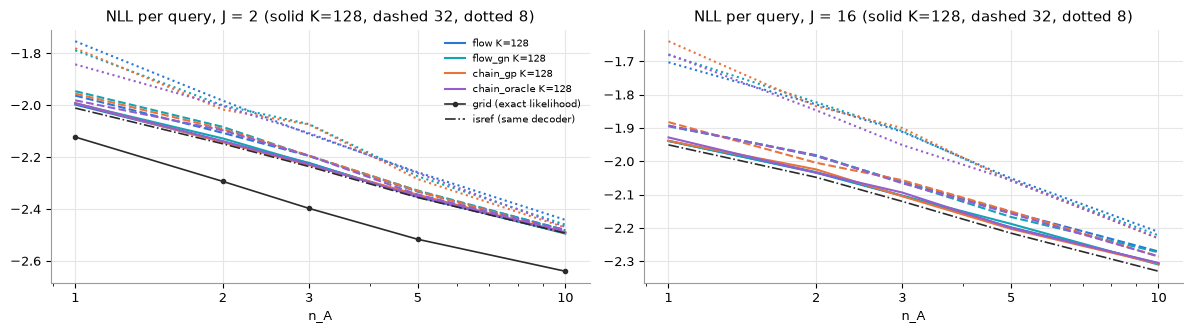

In [ ]:
tbl = NLL.groupby(["J", "method", "n_a"]).nll.mean().unstack("n_a")
display(tbl.round(3))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), sharey=False)
for ax, J in zip(axs, (2, 16)):
    for p in PROPS:
        for ls, K in zip((":", "--", "-"), (8, 32, 128)):
            m = NLL[(NLL.J == J) & (NLL.prop == p) & (NLL.K == K)].groupby("n_a").nll.mean()
            if len(m):
                ax.plot(m.index, m.values, color=C[p], ls=ls, lw=1.5, label=f"{p} K={K}" if ls == "-" else None)
    if J == 2:
        g = NLL[(NLL.J == 2) & (NLL.method == "grid")].groupby("n_a").nll.mean()
        ax.plot(g.index, g.values, color=INK, lw=1.2, marker="o", ms=3, label="grid (exact likelihood)")
    if ISR is not None:
        r = ISR[ISR.J == J].groupby("n_a").nll.mean()
        ax.plot(r.index, r.values, color=INK, lw=1.2, ls="-.", label="isref (same decoder)")
    ax.set(title=f"NLL per query, J = {J} (solid K=128, dashed 32, dotted 8)", xlabel="n_A", xscale="log")
    ax.set_xticks([1, 2, 3, 5, 10], [1, 2, 3, 5, 10])
axs[0].legend(frameon=False, fontsize=7); plt.tight_layout(); plt.show()

### V2.0 sanity (amended reference: isref)

In [ ]:
rows = []
if ISR is not None:
    ref = ISR[ISR.J == 2].set_index(["seed", "n_a", "task"]).nll
    for p in ("chain_oracle", "chain_gp", "flow"):
        z = paired(cell_mean(p, 128, 2), ref)
        for n, r in z.iterrows():
            rows.append({"proposal": p, "n_a": n, "K128 − isref": r["mean"], "seed_se": r["seed_se"]})
v20a = pd.DataFrame(rows); display(v20a.round(3) if len(v20a) else "isref not joined")
kl = DIAG[(DIAG.J == 2) & (DIAG.metric == "kl_post_q")].groupby(["proposal", "n_a", "seed"]).value.mean().unstack("seed").mean(axis=1).unstack("proposal")
display(kl.round(3))
ok_a = len(v20a) and bool((v20a[(v20a.proposal == "chain_oracle") & (v20a.n_a <= 3)]["K128 − isref"] <= 0.05).all())
ok_b = bool((kl["chain_oracle"] <= kl["chain_gp"] + 0.05).all())
V20 = bool(ok_a and ok_b)
print("V2.0: oracle vs isref", ok_a, "| oracle KL ≤ gp KL + 0.05", ok_b, "->", V20)

,proposal,n_a,K128 − isref,seed_se
0,chain_oracle,1,0.019,0.001
1,chain_oracle,2,0.010,0.000
2,chain_oracle,3,0.009,0.001
3,chain_oracle,5,0.004,0.001
4,chain_oracle,10,0.004,0.001
5,chain_gp,1,0.019,0.001
6,chain_gp,2,0.006,0.001
7,chain_gp,3,0.006,0.001
8,chain_gp,5,0.011,0.001
9,chain_gp,10,0.001,0.001


proposal,chain_gp,chain_oracle,flow,flow_gn
n_a,,,,
1,0.348,0.328,0.302,0.353
2,0.493,0.442,0.518,0.502
3,0.557,0.487,0.642,0.571
5,0.738,0.607,0.805,0.737
10,0.672,0.514,1.013,0.681


V2.0: oracle vs isref True | oracle KL ≤ gp KL + 0.05 True -> True


### V2.1 (primary), V2.1b, V2.2, V2.3: paired differences at K = 32

Δ = NLL(flow) − NLL(other), per task, mean per seed; positive = the other proposal is better. A criterion holds in a cell if it holds in each seed.

In [ ]:
out = {}
for other in ("chain_gp", "flow_gn", "chain_oracle"):
    for J in (2, 16):
        for K in (8, 32, 128):
            z = paired(cell_mean("flow", K, J), cell_mean(other, K, J))
            out[(other, J, K)] = z
show = pd.concat({k: v[["mean", "min_over_seeds", "task_se"]] for k, v in out.items() if k[2] == 32}, names=["vs", "J", "K"])
display(show.round(3))
def holds(other, J, thr=0.05):
    z = out[(other, J, 32)]
    cells = z.loc[[3, 5, 10]]
    return int((cells["min_over_seeds"] >= thr).sum())
V21 = {J: holds("chain_gp", J) for J in (2, 16)}
V21b = {J: holds("flow_gn", J) for J in (2, 16)}
P_V21 = all(v >= 2 for v in V21.values())
ess = DIAG[DIAG.metric == "ess_K32"].groupby(["J", "n_a", "seed", "proposal"]).value.mean().unstack("proposal")
e_ok = (ess["chain_gp"] > ess["flow"]).groupby(["J", "n_a"]).all()
P_V22 = all(int(e_ok.loc[J].loc[[3, 5, 10]].sum()) >= 2 for J in (2, 16))
v23 = {J: float(out[("chain_gp", J, 32)].loc[1, "mean"]) for J in (2, 16)}
nogo = all(float(out[("chain_gp", J, 32)].loc[n, "mean"]) < 0.02 for J in (2, 16) for n in (2, 3, 5, 10))
print("V2.1 cells (of 3, n_A ∈ {3,5,10}) with Δ ≥ 0.05 in every seed:", V21, "->", P_V21)
print("V2.1b flow_gn:", V21b)
print("V2.2 ESS/K(chain_gp) > ESS/K(flow) in ≥ 2 of 3 cells, both J:", P_V22)
print("V2.3 n_A = 1 Δ:", {J: round(v, 3) for J, v in v23.items()}, "(|Δ| ≤ 0.05 expected)")
print("NO-GO condition (Δ < 0.02 in every cell n_A ≥ 2, both J):", nogo)
display(ess.groupby(["J", "n_a"]).mean().round(3))

mean  min_over_seeds  task_se
vs           J  K  n_a                                
chain_gp     2  32 1   -0.008          -0.014    0.009
                   2   -0.015          -0.020    0.010
                   3   -0.001          -0.003    0.008
                   5   -0.002          -0.003    0.008
                   10   0.008           0.005    0.003
             16 32 1   -0.010          -0.022    0.009
                   2    0.020           0.009    0.009
                   3   -0.005          -0.016    0.008
                   5   -0.002          -0.006    0.006
                   10   0.015           0.011    0.006
flow_gn      2  32 1   -0.017          -0.022    0.011
                   2   -0.023          -0.026    0.011
                   3    0.001          -0.002    0.008
                   5   -0.004          -0.007    0.008
                   10   0.001          -0.001    0.003
             16 32 1    0.002          -0.008    0.008
                   2   -0.003          -0.016    0.008
                   3    0.002          -0.011    0.008
                   5    0.014           0.007    0.007
                   10   0.002          -0.001    0.006
chain_oracle 2  32 1    0.018           0.012    0.008
                   2   -0.010          -0.015    0.009
                   3   -0.001          -0.004    0.009
                   5    0.012           0.008    0.006
                   10   0.001          -0.001    0.004
             16 32 1    0.001          -0.012    0.008
                   2   -0.001          -0.017    0.008
                   3    0.004          -0.008    0.007
                   5    0.004          -0.003    0.007
                   10   0.015           0.012    0.005

V2.1 cells (of 3, n_A ∈ {3,5,10}) with Δ ≥ 0.05 in every seed: {2: 0, 16: 0} -> False
V2.1b flow_gn: {2: 0, 16: 0}
V2.2 ESS/K(chain_gp) > ESS/K(flow) in ≥ 2 of 3 cells, both J: False
V2.3 n_A = 1 Δ: {2: -0.008, 16: -0.01} (|Δ| ≤ 0.05 expected)
NO-GO condition (Δ < 0.02 in every cell n_A ≥ 2, both J): False


proposal  chain_gp  chain_oracle   flow  flow_gn
J  n_a                                          
2  1         0.779         0.757  0.831    0.775
   2         0.718         0.693  0.734    0.708
   3         0.687         0.653  0.684    0.665
   5         0.665         0.621  0.628    0.652
   10        0.621         0.587  0.547    0.622
16 1         0.693         0.684  0.766    0.685
   2         0.596         0.567  0.643    0.567
   3         0.517         0.487  0.559    0.501
   5         0.429         0.401  0.448    0.430
   10        0.346         0.339  0.328    0.324

### Calibration of q: rank of θ_true among q draws, and log q(θ_true)

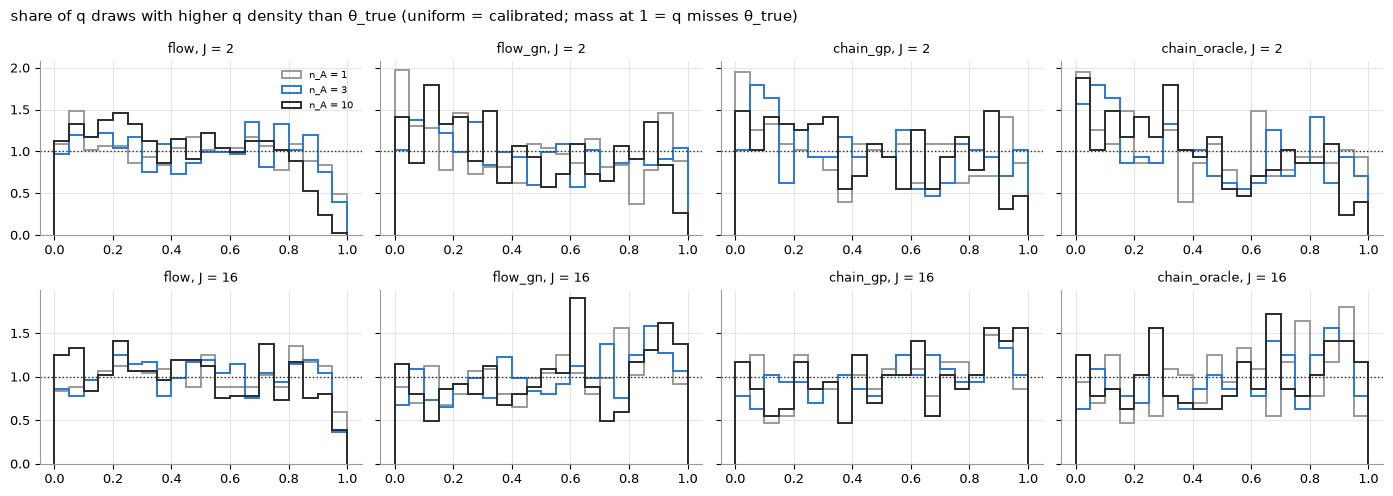

KS distance, n_A     1      2      3      5      10
J  proposal                                        
2  chain_gp       0.101  0.092  0.085  0.100  0.112
   chain_oracle   0.097  0.108  0.112  0.127  0.166
   flow           0.051  0.047  0.049  0.082  0.127
   flow_gn        0.094  0.098  0.095  0.096  0.116
16 chain_gp       0.068  0.066  0.080  0.073  0.078
   chain_oracle   0.072  0.077  0.069  0.084  0.077
   flow           0.024  0.036  0.037  0.041  0.079
   flow_gn        0.071  0.060  0.078  0.095  0.082

n_a                 1      2      3      5      10
J  proposal                                       
2  chain_gp      -2.20  -1.78  -1.48  -0.95  -0.13
   chain_oracle  -2.19  -1.72  -1.39  -0.85   0.04
   flow          -2.18  -1.81  -1.51  -1.01  -0.38
   flow_gn       -2.20  -1.79  -1.50  -0.96  -0.17
16 chain_gp     -22.33 -21.94 -21.63 -20.95 -19.96
   chain_oracle -22.31 -21.88 -21.55 -20.84 -19.66
   flow         -22.21 -21.76 -21.46 -20.95 -20.12
   flow_gn      -22.34 -21.94 -21.62 -20.96 -19.94

In [ ]:
fig, axs = plt.subplots(2, 4, figsize=(14, 5), sharey="row")
for r, J in enumerate((2, 16)):
    for c, p in enumerate(PROPS):
        ax = axs[r, c]
        for k, n in enumerate((1, 3, 10)):
            v = DIAG[(DIAG.J == J) & (DIAG.proposal == p) & (DIAG.metric == "rank_true") & (DIAG.n_a == n)].value
            ax.hist(v, bins=20, range=(0, 1), histtype="step", density=True, lw=1.4, color=["#9a9a9a", "#2a78d6", INK][k],
                    label=f"n_A = {n}")
        ax.axhline(1, color=INK, ls=":", lw=1); ax.set_title(f"{p}, J = {J}", fontsize=9)
axs[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("share of q draws with higher q density than θ_true (uniform = calibrated; mass at 1 = q misses θ_true)", x=0.01, ha="left")
plt.tight_layout(); plt.show()
ks = DIAG[DIAG.metric == "rank_true"].groupby(["J", "proposal", "n_a"]).value.apply(lambda v: stats.kstest(v, "uniform").statistic)
display(ks.unstack("n_a").round(3).rename_axis(columns="KS distance, n_A"))
display(DIAG[DIAG.metric == "logq_true"].groupby(["J", "proposal", "n_a"]).value.mean().unstack("n_a").round(2))

### KL(post ‖ q) at J = 2, and its dependence on σ_A (fixed fit noise 0.02)

n_a                          1      2      3      5      10
proposal     σ_A bin                                       
chain_gp     < 0.0125     0.363  0.595  0.999  1.078  1.005
             0.0125–0.02  0.339  0.336  0.358  0.442  0.420
             > 0.02       0.170  0.249  0.223  0.264  0.258
chain_oracle < 0.0125     0.398  0.651  0.740  0.803  0.877
             0.0125–0.02  0.195  0.318  0.312  0.310  0.239
             > 0.02       0.146  0.170  0.216  0.174  0.205
flow         < 0.0125     0.289  0.636  0.907  1.305  1.974
             0.0125–0.02  0.208  0.343  0.369  0.410  0.520
             > 0.02       0.097  0.222  0.241  0.272  0.344
flow_gn      < 0.0125     0.381  0.640  1.009  1.082  1.013
             0.0125–0.02  0.339  0.336  0.368  0.460  0.420
             > 0.02       0.170  0.250  0.223  0.274  0.258

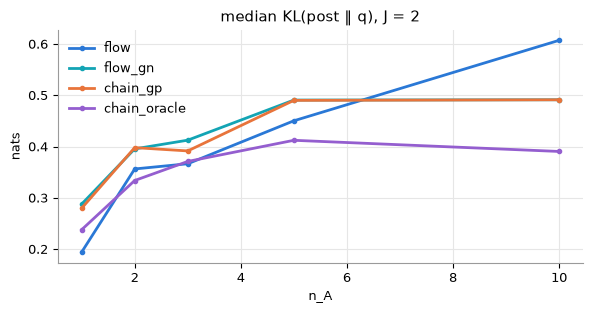

In [ ]:
import torch
from meta_pfn.experimental.air.train import eval_tasks
# σ_A per task from the run's task_info (the tasks are generated on the run device; a CPU regeneration differs)
sa = INFO[INFO.J == 2].set_index("task").sig_a
k2 = DIAG[(DIAG.J == 2) & (DIAG.metric == "kl_post_q")].copy(); k2["sig_a"] = sa.reindex(k2.task).to_numpy()
k2["σ_A bin"] = pd.cut(k2.sig_a, [0.005, 0.0125, 0.02, 0.03], labels=["< 0.0125", "0.0125–0.02", "> 0.02"])
display(k2.groupby(["proposal", "σ_A bin", "n_a"], observed=True).value.median().unstack("n_a").round(3))
fig, ax = plt.subplots(figsize=(6, 3.2))
for p in PROPS:
    m = k2[k2.proposal == p].groupby("n_a").value.median()
    ax.plot(m.index, m.values, color=C[p], marker="o", ms=3, label=p)
ax.set(title="median KL(post ‖ q), J = 2", xlabel="n_A", ylabel="nats"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

### V2.4: the flow − chain gap by the number of branches of g

In [ ]:
d = (cell_mean("flow", 32, 0) if False else None)
rows = []
for J in (2, 16):
    a, b = cell_mean("flow", 32, J), cell_mean("chain_gp", 32, J)
    z = (a - b).rename("d").reset_index()
    z = z.merge(INFO[INFO.J == J][["task", "branches"]], on="task")
    z["branches"] = z.branches.clip(upper=4).astype(int).astype(str).replace({"4": "4+"})
    rows.append(z.assign(J=J))
bz = pd.concat(rows)
display(bz[bz.n_a >= 3].groupby(["J", "branches"]).d.agg(["mean", "count"]).round(3))
display(bz.groupby(["J", "n_a", "branches"]).d.mean().unstack("branches").round(3))

mean  count
J  branches              
2  1        -0.001    729
   2         0.002    594
   3         0.000    558
   4+        0.007    423
16 1        -0.007    900
   2         0.003    549
   3         0.018    486
   4+        0.005    369

branches      1      2      3     4+
J  n_a                              
2  1     -0.000 -0.004 -0.028  0.002
   2      0.010 -0.004 -0.034 -0.048
   3     -0.011  0.002  0.004  0.004
   5      0.006  0.008 -0.016 -0.013
   10     0.003 -0.003  0.012  0.028
16 1     -0.006 -0.022  0.002 -0.018
   2      0.036  0.039  0.036 -0.065
   3     -0.003 -0.009 -0.005 -0.006
   5     -0.016  0.005  0.017 -0.003
   10    -0.003  0.014  0.042  0.024

### Build cost per task (seconds; CPU/GPU as run)

In [ ]:
display(DIAG[DIAG.metric == "build_s"].groupby(["J", "proposal", "n_a"]).value.mean().unstack("n_a").round(3))

n_a                 1      2      3      5      10
J  proposal                                       
2  chain_gp      0.102  0.101  0.105  0.114  0.136
   chain_oracle  0.096  0.099  0.102  0.107  0.123
   flow_gn       0.052  0.051  0.052  0.055  0.061
16 chain_gp      0.120  0.151  0.197  0.285  0.488
   chain_oracle  0.105  0.132  0.160  0.221  0.362
   flow_gn       0.075  0.095  0.125  0.177  0.301

### Criteria summary

In [ ]:
go = V20 and P_V21 and P_V22
verdict = "GO" if go else ("NO-GO" if nogo else "INCONCLUSIVE")
summ = pd.DataFrame([("V2.0 sanity (isref)", V20), ("V2.1 primary (chain_gp vs flow, K=32)", f"{V21} -> {P_V21}"),
                     ("V2.1b flow_gn vs flow (reported)", V21b), ("V2.2 ESS/K", P_V22),
                     ("V2.3 n_A = 1 (reported)", {J: round(v, 3) for J, v in v23.items()}),
                     ("NO-GO condition", nogo), ("rule outcome", verdict)], columns=["criterion", "value"])
display(summ)
print("seeds:", SEEDS, "(the rule needs all 3 seeds)" if NS < 3 else "")

,criterion,value
0,V2.0 sanity (isref),True
1,"V2.1 primary (chain_gp vs flow, K=32)","{2: 0, 16: 0} -> False"
2,V2.1b flow_gn vs flow (reported),"{2: 0, 16: 0}"
3,V2.2 ESS/K,False
4,V2.3 n_A = 1 (reported),"{2: -0.008, 16: -0.01}"
5,NO-GO condition,False
6,rule outcome,INCONCLUSIVE


seeds: [np.int64(0), np.int64(1), np.int64(2)] 


## Interpretation

Three seeds (sweeps `pilot_20261104-001215`, `-004520`, `-011821`; 2 DONE members each, none failed, started or missing),
256 tasks per (J, n_A), the decoders and flow proposals of AIR pilot 3. The `flow` rows reproduce pilot 3's `qis`
at Σ = 0 on the same tasks: K = 128 within 0.002 nats for every seed; K = 32 within 0.005 for seeds 0 and 1 and
−0.015 / +0.017 (J = 2 / 16) for seed 2, where the per-task MC spread at K = 32 is about 0.2 nats (SE ≈ 0.006).

**Result: the explicit chain proposal is as good as the flow, not better.** At K = 32 the gain
NLL(flow) − NLL(chain_gp) lies in [−0.015, +0.020] nats in every cell (task SE ≈ 0.003–0.010); the pre-registered
0.05 is not reached anywhere.

| criterion | outcome |
|---|---|
| V2.0 sanity: chain_oracle K = 128 within 0.05 of isref (J = 2, n_A ≤ 3); oracle KL ≤ gp KL + 0.05 | **pass** (0.009–0.019; KL 0.33–0.49 vs 0.35–0.56) |
| V2.1 primary: Δ ≥ 0.05 at K = 32 in ≥ 2 of n_A ∈ {3, 5, 10}, both J, every seed | **fail** (0 of 3 cells at either J; largest mean Δ +0.015 at n_A ≥ 3) |
| V2.1b flow_gn vs flow (reported) | 0 cells; Δ in [−0.023, +0.014] |
| V2.2 ESS/K higher for the chain | **fail**: higher only at J = 2, n_A ≥ 5 (0.67 vs 0.63, 0.62 vs 0.55) and J = 16, n_A = 10 (0.35 vs 0.33) |
| V2.3 n_A = 1 within ±0.05 (reported) | holds (−0.008 / −0.010) |
| V2.4 gap by branches (reported) | no trend; cell means within ±0.07, pooled per branch count within ±0.02 |
| NO-GO condition: Δ < 0.02 in every cell with n_A ≥ 2, both J | **not met, narrowly**: one cell, J = 16, n_A = 2, has mean Δ = +0.020 |
| **rule outcome** | **INCONCLUSIVE** |

**Why nothing can win here: no headroom at K = 32.** At J = 2 the flow at K = 32 is only 0.048 / 0.042 / 0.041 /
0.023 / 0.012 nats above the prior-IS reference (isref, same decoder) for n_A = 1 / 2 / 3 / 5 / 10, and at K = 128
it is within 0.001–0.014. Even a perfect proposal could gain at most ≈ 0.04 nats at n_A = 3 and ≈ 0.01 at n_A = 10,
so V2.1's 0.05 threshold was unattainable in two of its three cells. This is a pre-registration flaw (the threshold
was set without the K = 32 → isref headroom from notebook 11 in view), not a property of the chain. It matches
notebook 11: the proposal costs 0.02–0.03 nats at K = 32, and the decoder gap is 0.11–0.16. The distance from isref
to the exact `grid` reference (0.11–0.16 nats at J = 2) is the decoder, shared by all four proposals. Notebook 13 makes
the same point for MTPFN: neither model's remaining distance to Bayes is the warp or proposal.

**What the chain does fix: the posterior shape (pilot 3's P3.1).** KL(post ‖ q) at J = 2 grows with n_A for the
flow (0.30 → 1.01), but stays at 0.35 → 0.67 for chain_gp and 0.33 → 0.51 for chain_oracle. The explicit
correspondence + Laplace route tracks the posterior as it sharpens; the pooled flow proposes too wide. It does not
show in NLL because the defensive prior share and K = 32 IS already absorb the flow's excess width.

**Failure analysis, as pre-registered:**
- *GP emissions* (chain_gp vs chain_oracle): the true g lowers KL by 0.02–0.16 (most at n_A = 10). NLL is
  unchanged (within ±0.03 at K = 32, ≤ 0.007 apart at K = 128). The GP on B is not the bottleneck.
- *Chain vs flow seeds* (chain_gp vs flow_gn): practically identical in NLL, KL (0.35/0.49/0.56/0.74/0.67 vs
  0.35/0.50/0.57/0.74/0.68), ESS/K and PIT. Once GN + Laplace runs, where the seeds come from does not matter;
  the refinement's §1 (flow seeds + GN) is the cheaper route to the same q.
- *Laplace width* (KL by σ_A): for every GN-based proposal, KL is 2–4× larger for σ_A < 0.0125 (chain_gp ≈ 1.0 at
  n_A ≥ 3) than for σ_A > 0.02 (≈ 0.25). The fixed fit noise 0.02 is too wide when the true noise is small. The
  oracle shows the same pattern, so it is the fit noise, not the emissions. A σ_A-marginal (or profiled) fit would
  narrow q further, but per the headroom argument it would not move NLL at K ≥ 32.
- *SBC/PIT*: the flow is the best-calibrated proposal (KS 0.02–0.13); the GN-based ones sit at 0.06–0.17. They are
  mode-concentrated, with a slight shape mismatch from the fixed-noise Laplace. That is harmless for IS, given
  the defensive mixture.
- *Cost*: chain_gp builds in 0.10–0.49 s per task, flow_gn in 0.05–0.30 s; both grow with n_A at J = 16.

**Proposed verdict: INCONCLUSIVE as registered, read as a practical NO-GO for the question.** The rule outcome is
INCONCLUSIVE only because one cell sits on the 0.02 NO-GO edge. Substantively there is nothing for a better
proposal to win in d = 1 at K ≥ 32: proposal quality is no longer AIR's bottleneck; the decoder is. A second pilot
of this question is not proposed. The chain stays in `experimental/` as a reference for d ≥ 2, where the flow's
excess width may cost more and the KL improvement may become NLL. Whether to test that is a scope decision for
the d = 2 stage of AIR (pilot 3 rule 1), not a rerun here.


## Verdict

Proposed in the interpretation above; recorded by the user with `just decide`.